In [27]:
import numpy as np
import pandas as pd


In [28]:
ocr_data = pd.read_parquet("../data/interim/ocr.parquet")

ocr_data.head(3)

,path,label,split,text,mean_confidence,nb_words,rotation,tesseract_version,tesseract_lang,tesseract_config,rotation_threshold
0,train/2079129860.jpg,Email,train,"Horn, Bonnie T.\nFrom: Waish, Michael A. (Madd...",91.911111,45,0,5.5.3,eng,--oem 1 --psm 3,74
1,train/2085119305a.jpg,Email,train,"Chang, Yen\nFrom: Chang, Yen\nSent: Monday, Ma...",88.418605,43,0,5.5.3,eng,--oem 1 --psm 3,74
2,train/92206285.jpg,ADVE,train,SURGEON GENERAL'S WARNING: Quitting Smoking\nN...,91.076923,13,0,5.5.3,eng,--oem 1 --psm 3,74


In [29]:
ocr_data.shape

(2737, 11)

In [30]:
ocr_data.columns

Index(['path', 'label', 'split', 'text', 'mean_confidence', 'nb_words',
       'rotation', 'tesseract_version', 'tesseract_lang', 'tesseract_config',
       'rotation_threshold'],
      dtype='str')

In [31]:
ocr_data['text'].isna().sum()

np.int64(0)

In [32]:
ocr_data_order_on_confidence = ocr_data.dropna(subset=["mean_confidence"]).sort_values("mean_confidence")

In [33]:
less_confidence = ocr_data.dropna(subset = ["mean_confidence"]).nsmallest(30, "mean_confidence")

less_confidence[["path", "label", "mean_confidence", "nb_words"]]

,path,label,mean_confidence,nb_words
2074,train/60019614.jpg,Note,18.354839,155
657,train/501303452+-3452.jpg,ADVE,18.812500,48
1193,train/2048858141.jpg,Note,22.500000,16
270,train/503781513.jpg,ADVE,22.586207,116
1562,train/2058030605.jpg,Form,23.785714,84
2140,train/2025319413.jpg,Note,24.826087,69
671,train/502599535+-9535.jpg,ADVE,25.298077,104
243,train/2023192377.jpg,Note,26.139241,237
2262,train/503782317.jpg,ADVE,27.406015,133
2569,train/10030014.jpg,News,27.521368,117


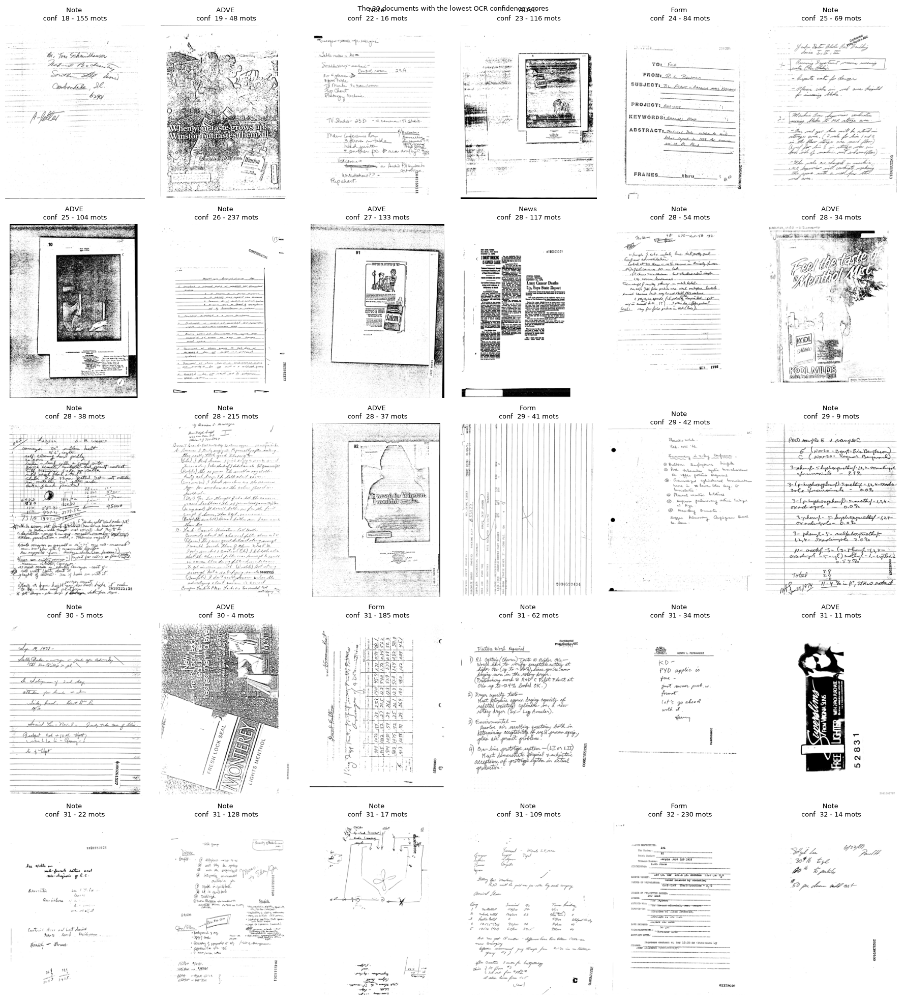

In [34]:
import math
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

_ROOT_PATH = Path.cwd().parent
_IMAGES_DIR = "data/raw"
_N_COLS = 6

def show_grid(df, root = _ROOT_PATH/_IMAGES_DIR, n_cols = _N_COLS) :
    n_rows = math.ceil(len(df) / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize = (3* n_cols, 4* n_rows))
    axes = np.atleast_1d(axes).ravel()

    for ax, (_, r) in zip(axes, df.iterrows()):
        with Image.open(_ROOT_PATH/_IMAGES_DIR / r["path"]) as img :
            img.thumbnail((400, 400))
            ax.imshow(img, cmap="gray")
            
        ax.set_title(f"{r['label']} \nconf {r['mean_confidence'] : .0f} - {int(r['nb_words'])} mots", fontsize = 9)
        ax.axis("off")
        
    for ax in axes[len(df):]:
        ax.axis("off")
        

    fig.suptitle("The 30 documents with the lowest OCR confidence scores", fontsize = 9)
    plt.tight_layout()
    plt.show()


show_grid(ocr_data_order_on_confidence.iloc[0:30])

*Out of 30, 13 images were flipped*

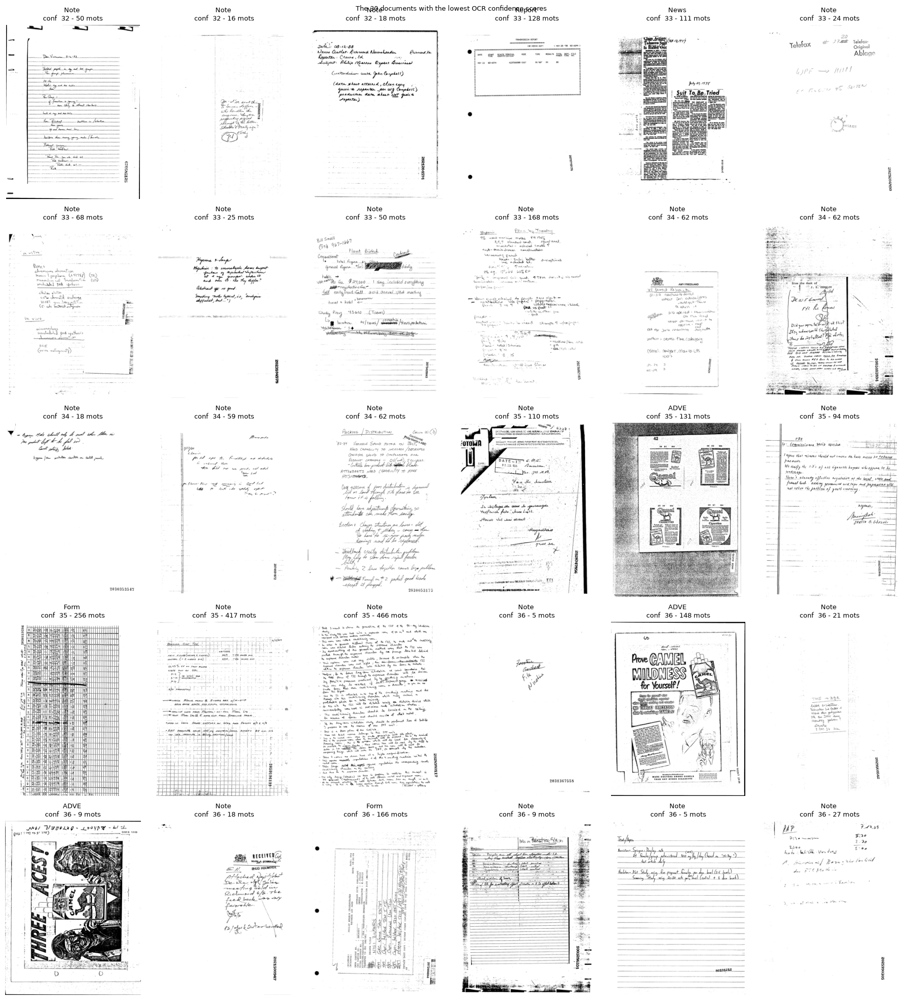

In [35]:
show_grid(ocr_data_order_on_confidence.iloc[30:60])

*out of 30, 17 images were flipped*

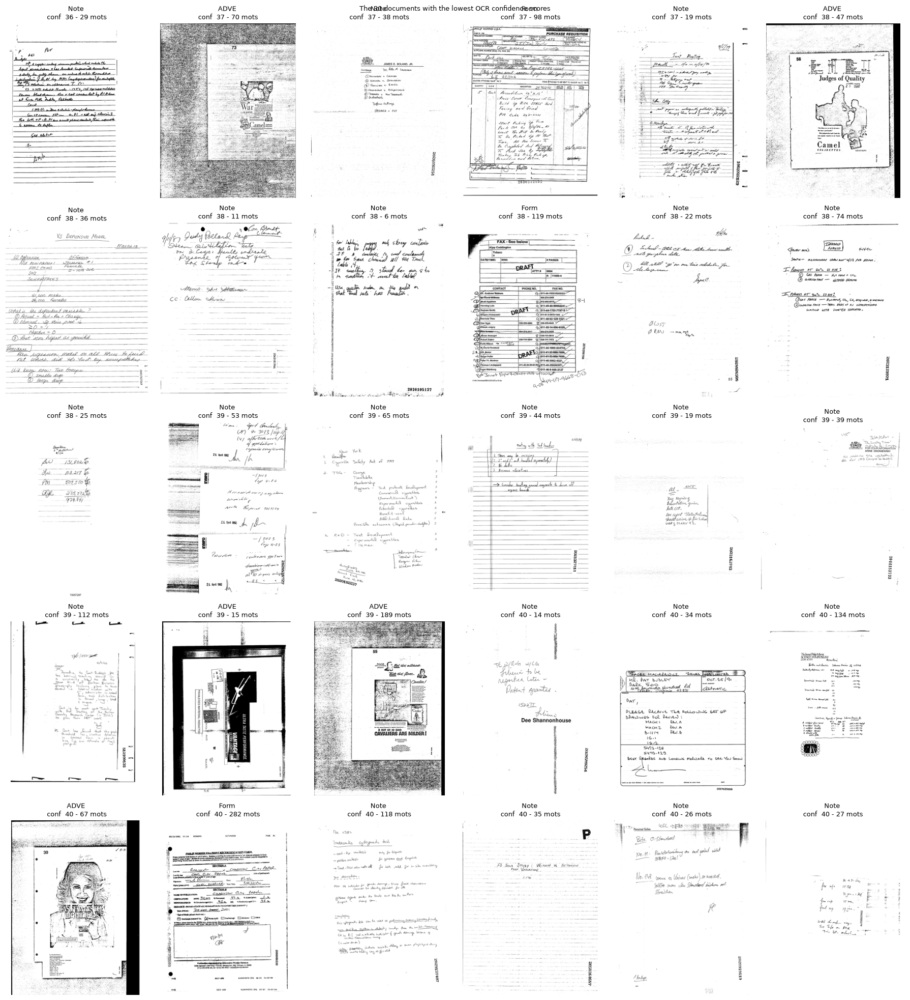

In [36]:
show_grid(ocr_data_order_on_confidence.iloc[60:90])

*out of 30, 12 images were flipped*

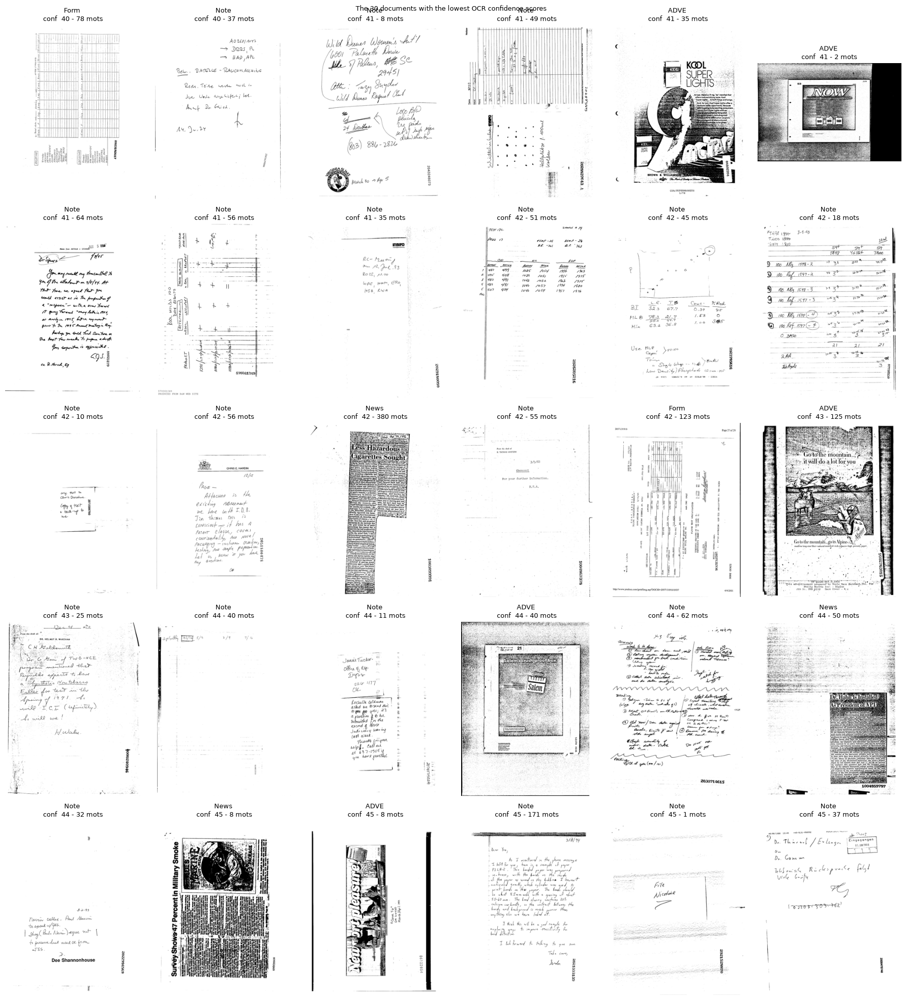

In [37]:
show_grid(ocr_data_order_on_confidence.iloc[90:120])

*out of 30, 15 images were flipped*

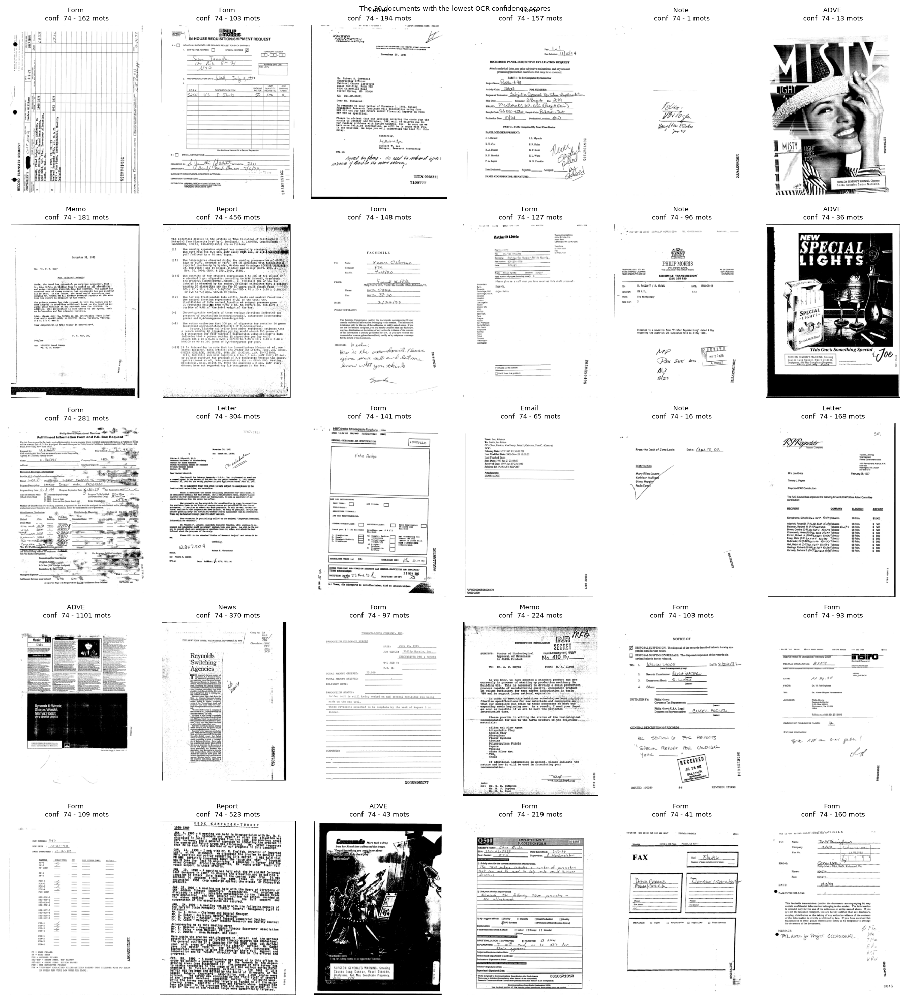

In [38]:
show_grid(ocr_data_order_on_confidence.iloc[500:530])

*out of 30, 3 images were flipped*

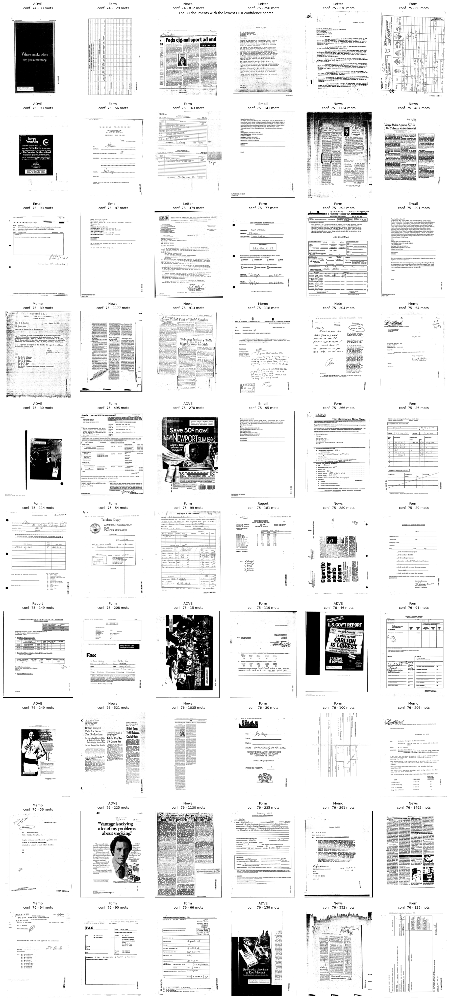

In [39]:
show_grid(ocr_data_order_on_confidence.iloc[530:590])

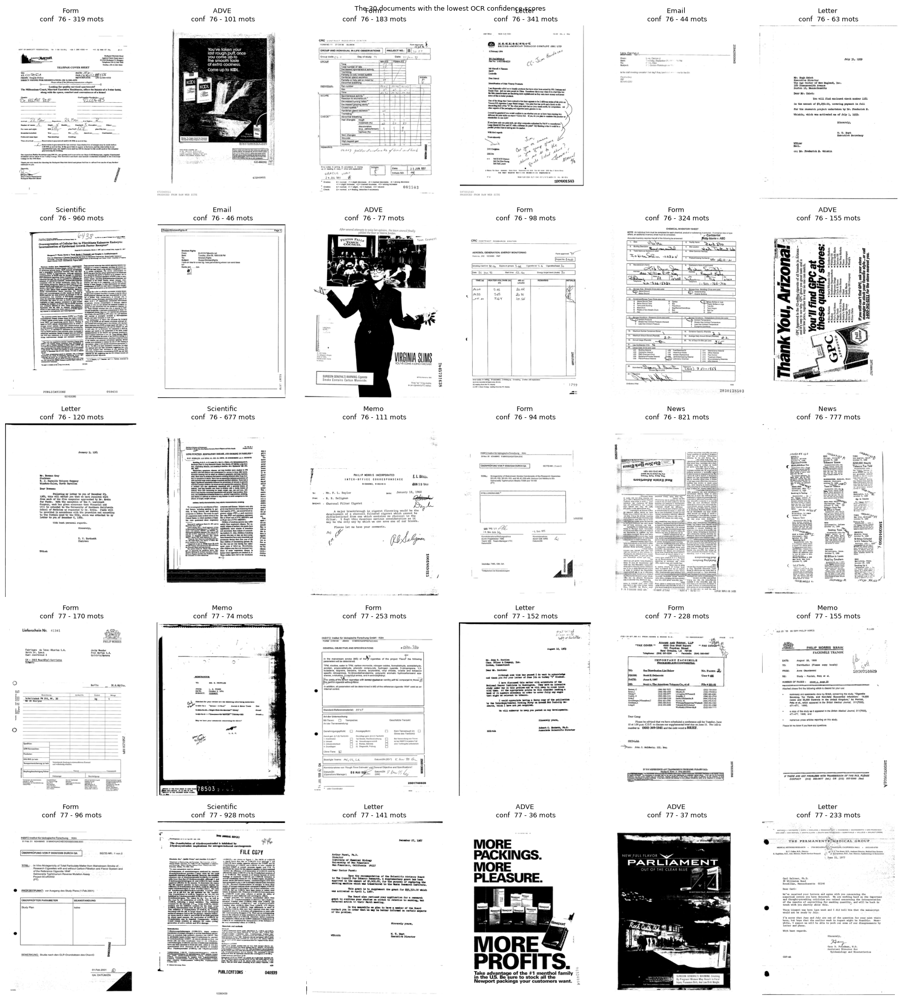

In [40]:
show_grid(ocr_data_order_on_confidence.iloc[600:630])

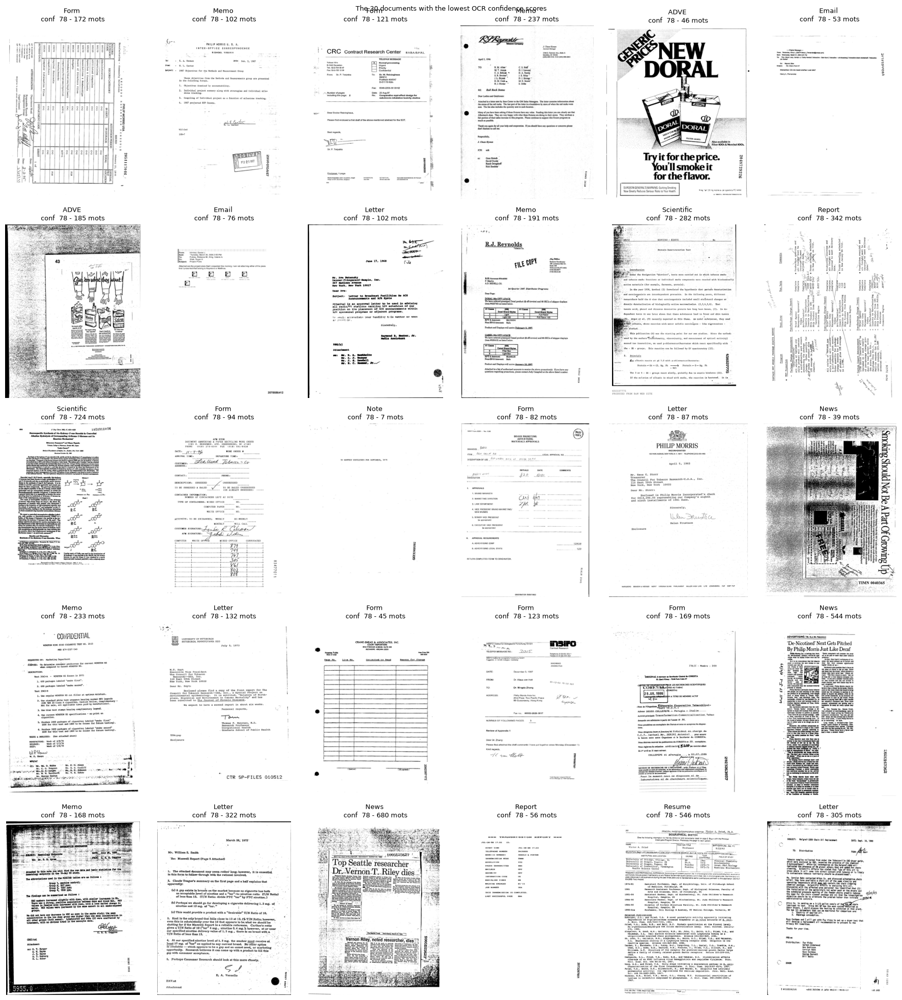

In [41]:
show_grid(ocr_data_order_on_confidence.iloc[660:690])

*Starting at confidence level 76, there really aren't many images taken.*

In [42]:
ocr_data[ocr_data["nb_words"] == 0]

,path,label,split,text,mean_confidence,nb_words,rotation,tesseract_version,tesseract_lang,tesseract_config,rotation_threshold
1620,train/501947737_501947738.jpg,Note,train,,NaN,0,0,5.5.3,eng,--oem 1 --psm 3,74


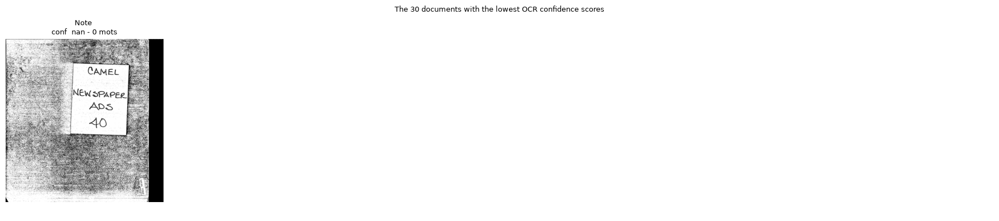

In [43]:
ocr_data_0_word = ocr_data[ocr_data["nb_words"] == 0]
show_grid(ocr_data_0_word)

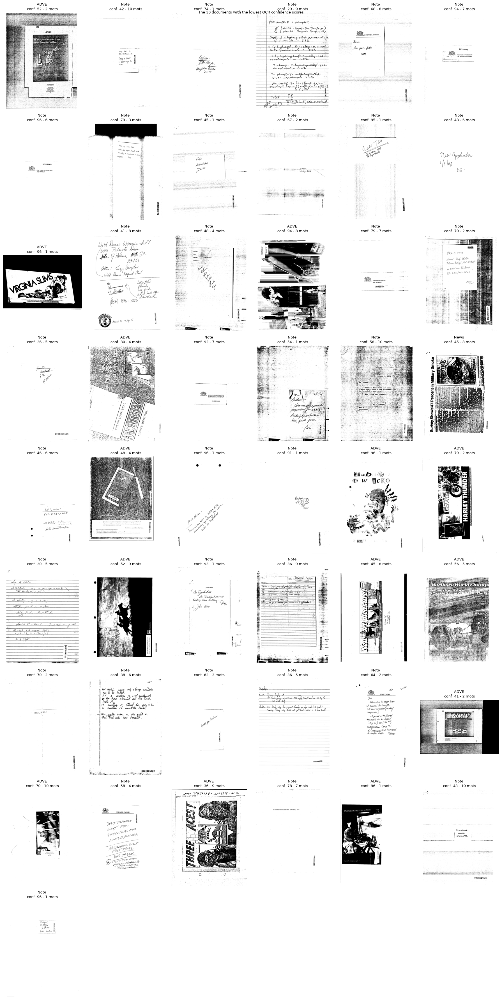

In [44]:
ocr_data_min_words = ocr_data[(ocr_data["nb_words"]  <= 10) & (ocr_data["nb_words"]  > 0)]
show_grid(ocr_data_min_words)

In [45]:
ocr_data_min_words.shape

(49, 11)

In [46]:
ocr_data_min_words["label"].value_counts()

label
Note    34
ADVE    14
News     1
Name: count, dtype: int64

/var/folders/zb/5qjkz41s5tg0qgdypxq_tnr80000gn/T/ipykernel_11941/2681417658.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False, showfliers=True, flierprops={"markersize": 2, "alpha": 0.4})
/var/folders/zb/5qjkz41s5tg0qgdypxq_tnr80000gn/T/ipykernel_11941/2681417658.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False, showfliers=True, flierprops={"markersize": 2, "alpha": 0.4})


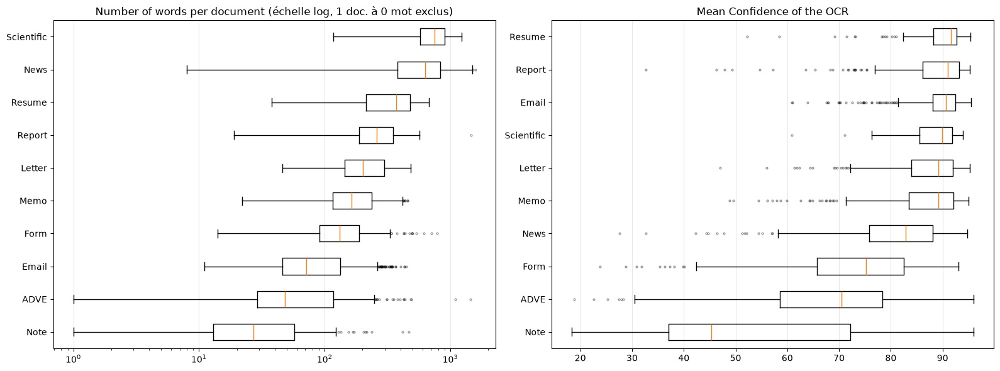

In [47]:
data = ocr_data.dropna(subset = ["text"])

def boxplot_per_class(ax, data, column, title, log=False):
    if log:
        n_zero = (data[column] <= 0).sum()
        data = data[data[column] > 0]   

    order = data.groupby("label")[column].median().sort_values().index
    values = [data.loc[data["label"] == c, column].dropna() for c in order]

    ax.boxplot(values, vert=False, showfliers=True, flierprops={"markersize": 2, "alpha": 0.4})
    ax.set_yticks(range(1, len(order) + 1), order)
    ax.grid(axis="x", alpha=0.3)

    if log:
        ax.set_xscale("log")
        title += f" (échelle log, {n_zero} doc. à 0 mot exclus)"
    ax.set_title(title)
    
fig, axes = plt.subplots(1, 2, figsize = (16, 6))
boxplot_per_class(axes[0], data, "nb_words", "Number of words per document", log = True)
boxplot_per_class(axes[1], data, "mean_confidence", "Mean Confidence of the OCR")
plt.tight_layout()
plt.show()

In [48]:
data = ocr_data.dropna(subset=["text"]).copy()
data["doc_id"] = data["path"].map(lambda p: Path(p).stem)    


data["id_exact"] = data.apply(lambda r: r["doc_id"] in r["text"], axis=1)


data["id_digits"] = data.apply(
    lambda r: r["doc_id"] in "".join(ch for ch in r["text"] if ch.isdigit()), axis=1
)

print(f"Id found(exact)     : {data['id_exact'].mean():.1%}")
print(f"Id found(tolérant)  : {data['id_digits'].mean():.1%}")

Id found(exact)     : 9.1%
Id found(tolérant)  : 9.5%


In [49]:
(data.groupby("label")[["id_exact", "id_digits"]].mean() * 100).round(1).sort_values("id_digits")

,id_exact,id_digits
label,,
Letter,0.0,0.0
Resume,0.0,0.0
Memo,0.4,0.4
Scientific,1.1,1.1
Report,1.2,1.2
News,5.4,5.4
Form,6.4,7.1
ADVE,8.1,10.2
Note,18.8,19.4


In [50]:
for _, r in data[data["id_exact"]].sample(5, random_state=0).iterrows():
    lignes = [l for l in r["text"].splitlines() if r["doc_id"] in l]
    print(f"{r['label']:<11} {r['doc_id']}  →  {lignes}")

Email       2080185536  →  ['2080185536']
Note        2065354661  →  ['2065354661']
Email       2078874121  →  ['2078874121']
Email       2078851793  →  ['2078851793']
Email       2070361099  →  ['2070361099 Page 1']


In [51]:
train = ocr_data[(ocr_data["split"] == "train")].dropna(subset=["mean_confidence"])
ratio = 600 / 2737    

quantile_threshold = train["mean_confidence"].quantile(ratio)

rang = round(ratio * len(train))      
threshold_rank = train["mean_confidence"].sort_values().iloc[rang - 1]

print(f"Quantile {ratio:.1%} of train : {quantile_threshold:.2f}")
print(f"Rank {rang} of train            : {threshold_rank:.2f}")

Quantile 21.9% of train : 76.20
Rank 420 of train            : 76.19


## OCR Analysis — Conclusions

### 1. OCR run
- All **2,737 documents** were processed, with **0 errors** and **0 missing documents** in the consolidated Parquet file (`data/interim/ocr.parquet`).
- Measured time: about **0.9 s per document**.
- The run was interrupted and restarted: the 1,504 documents already cached were skipped without recomputation. **Cache-based resumption works** (idempotence verified under real conditions).

### 2. Rotated pages
- Method: documents sorted by ascending mean confidence, then inspected visually in batches of 30.
  - up to rank ~450-500: **10 to 17 rotated pages per batch of 30**;
  - up to rank ~600: 1 to 3 per batch;
  - beyond: almost none (at most 1).
- Estimate: **about 150 to 200 rotated pages, i.e. 6 to 7% of the dataset**. The problem is too frequent to be ignored.
- Rotated pages are **concentrated in the ~600 lowest-confidence documents**: mean confidence is a good detector.

### 3. Empty or nearly empty documents
- **2 documents** have no words at all (both Note).
- **42 documents** have 10 words or fewer: **31 Note**, 10 ADVE and 1 Memo.
- About **19% of Notes** therefore have almost no usable text. For these documents, only the **image** can decide: a concrete argument for fusion.

### 4. Indicators by class
- **Rich, reliable text** (median confidence around 88-92): Resume, Report, Email, Scientific, Letter, Memo.
- **Noisy or sparse text**: News (median ~82), Form (~73), ADVE (~63) and above all **Note (~40)**. These are also the classes affected by handwriting, complex layouts and rotated pages.
- Word count: Scientific and News produce the most text (several hundred words), Note and ADVE the least (a few dozen).
- **Takeaway**: the text modality will be strong for some classes and weak for others. The two modalities should therefore be complementary.

### 5. Bates numbers (document ID in the text)
| Class | Exact ID found (%) | ID digits found (%) |
|---|---|---|
| Email | 29.6 | 30.1 |
| ADVE | 13.2 | 14.2 |
| Note | 12.7 | 12.7 |
| Form | 11.2 | 11.9 |
| News | 8.6 | 9.7 |
| Report | 2.4 | 2.4 |
| Scientific | 1.1 | 1.1 |
| Memo | 0.4 | 0.4 |
| Letter | 0.0 | 0.0 |
| Resume | 0.0 | 0.0 |

- The presence of the number depends on the **class** (30% of emails, never in Letters or Resumes). It is not related to the content but to how the pages were stamped and scanned: an **acquisition bias**, in the same family as the fax bias.
- Risk: the model could learn "a long number in the text means Email".

### 6. Decisions
- **Rotated page correction**:
  - confidence threshold set at **74**, determined on the **training set only** (21.9% quantile = 73.94; rank 420 = 73.86), equivalent to the ~600 lowest-confidence documents;
  - if the confidence at 0° is **below the threshold** (or there are no words), OCR is rerun at **90°, 180° and 270°**, and the orientation with the **highest confidence** is kept;
  - it is a **fixed threshold**, not a ranking: the rule applies document by document, so it works the same way in training and in production (Phase 3);
  - estimated cost: about **27 minutes** (3 orientations × ~600 documents), instead of more than 2 hours for the whole dataset;
  - the **selected angle** is recorded: it can also be used to straighten the image for the image encoder.
- **Cache update**:
  - the threshold and angle are added to the settings stored in each JSON file;
  - a JSON file is up to date if it contains the current settings. Otherwise, above the threshold, only `rotation = 0` is added; below it, the 3 other orientations are computed, reusing the 0° result already stored;
  - confidence alone cannot tell whether a JSON file is up to date: a handwritten Note would stay below the threshold after rotation and be reprocessed forever.
- **Text cleaning**: remove the Bates numbers from the OCR text to eliminate this bias (see method below).

# After rotation

In [56]:
ocr_data_rotate = pd.read_parquet("../data/interim/ocr.parquet")

In [57]:
ocr_data_rotate.head(3)

,path,label,split,text,mean_confidence,nb_words,rotation,tesseract_version,tesseract_lang,tesseract_config,rotation_threshold
0,train/2079129860.jpg,Email,train,"Horn, Bonnie T.\nFrom: Waish, Michael A. (Madd...",91.911111,45,0,5.5.3,eng,--oem 1 --psm 3,74
1,train/2085119305a.jpg,Email,train,"Chang, Yen\nFrom: Chang, Yen\nSent: Monday, Ma...",88.418605,43,0,5.5.3,eng,--oem 1 --psm 3,74
2,train/92206285.jpg,ADVE,train,SURGEON GENERAL'S WARNING: Quitting Smoking\nN...,91.076923,13,0,5.5.3,eng,--oem 1 --psm 3,74


In [60]:
ocr_data_rotate[ocr_data_rotate['rotation'] != 0].shape

(400, 11)

In [61]:
rotated = ocr_data_rotate[ocr_data_rotate['rotation'] != 0]
rotated["rotation"].value_counts().sort_index()

rotation
90      34
180     62
270    304
Name: count, dtype: int64

In [62]:
per_class = pd.DataFrame({
    "redresses": rotated["label"].value_counts(),
    "total": ocr_data["label"].value_counts(),
}).fillna(0).astype(int)
per_class["part_%"] = (per_class["redresses"] / per_class["total"] * 100).round(1)
per_class.sort_values("part_%", ascending=False)

,redresses,total,part_%
label,,,
ADVE,94,197,47.7
Note,77,165,46.7
Form,115,312,36.9
News,39,185,21.1
Report,17,251,6.8
Memo,23,471,4.9
Letter,16,380,4.2
Resume,4,121,3.3
Email,13,565,2.3


In [63]:
pd.crosstab(rotated["label"], rotated["rotation"], margins=True)

rotation,90,180,270,All
label,,,,
ADVE,8,19,67,94
Email,0,0,13,13
Form,4,17,94,115
Letter,1,0,15,16
Memo,1,0,22,23
News,1,12,26,39
Note,17,12,48,77
Report,2,2,13,17
Resume,0,0,4,4


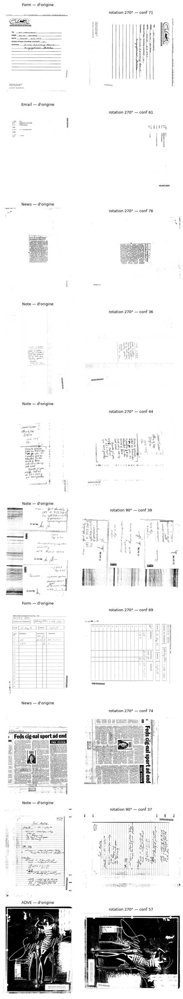

In [65]:
def display_before_after(df, n=10, thumb_size=300, random_state=0):
    """Show each document as stored (left) and rotated by its `rotation` (right)."""
    sample = df.sample(min(n, len(df)), random_state=random_state)
    fig, axes = plt.subplots(len(sample), 2, figsize=(7, 3.5 * len(sample)))
    axes = axes.reshape(-1, 2)

    for (ax_before, ax_after), (_, r) in zip(axes, sample.iterrows()):
        with Image.open(_ROOT_PATH / _IMAGES_DIR / r["path"]) as img:
            after = img.rotate(r["rotation"], expand=True)
            before = img.copy()
        before.thumbnail((thumb_size, thumb_size))
        after.thumbnail((thumb_size, thumb_size))

        ax_before.imshow(before, cmap="gray")
        ax_before.set_title(f"{r['label']} — d'origine", fontsize=9)
        ax_after.imshow(after, cmap="gray")
        ax_after.set_title(f"rotation {r['rotation']}° — conf {r['mean_confidence']:.0f}", fontsize=9)
        for ax in (ax_before, ax_after):
            ax.axis("off")

    plt.tight_layout()
    plt.show()

display_before_after(rotated, n=10)